In [1]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
bank_directory = os.path.join(project_folder, 'analyses', 'basis meta neuron bank', 'saved', 'opticflow')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
from numpy import linalg as la
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

2024-02-07 22:59:44.741351: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-02-07 22:59:44.801109: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-02-07 22:59:44.801143: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-02-07 22:59:44.802677: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-02-07 22:59:44.812709: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-02-07 22:59:44.813602: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [28]:
N = 93
K = 1

V_width = 1
# V_E_buffer_array = np.arange(2,22).astype(int)
V_E_buffer_array = np.array([0,20])
E_width = 1

In [29]:
sweep_dims = (len(V_E_buffer_array),)
bank_data = np.zeros(sweep_dims, dtype=object)
basis_neurons = np.zeros(sweep_dims, dtype=object)

for i, V_E_buffer in enumerate(V_E_buffer_array):
    load_path = os.path.join(bank_directory, f'({V_width},{V_E_buffer},{E_width}) K={K}.dat')
    with open(load_path, 'rb') as f:
        data_dict = pickle.load(f)
    basis_neurons[i] = data_dict["basis_vectors"]
    bank_data[i] = data_dict

stim = data_dict["mov_name"]

In [48]:
ref = basis_neurons[0]
for i in range(len(V_E_buffer_array)):
    for k in range(K):
        cur_leading = basis_neurons[i][:,k]
        cur_sign = np.sign(ref[:,k] @ cur_leading)
        # basis_neurons[i][:,k] *= cur_sign

B = [a for a in basis_neurons]
A = [a["meta_neurons"] for a in bank_data]


In [70]:
j = 1
q = B[j].T @ A[j]

Text(0.5, 0, 'overlap $q_2$ with second basis vector')

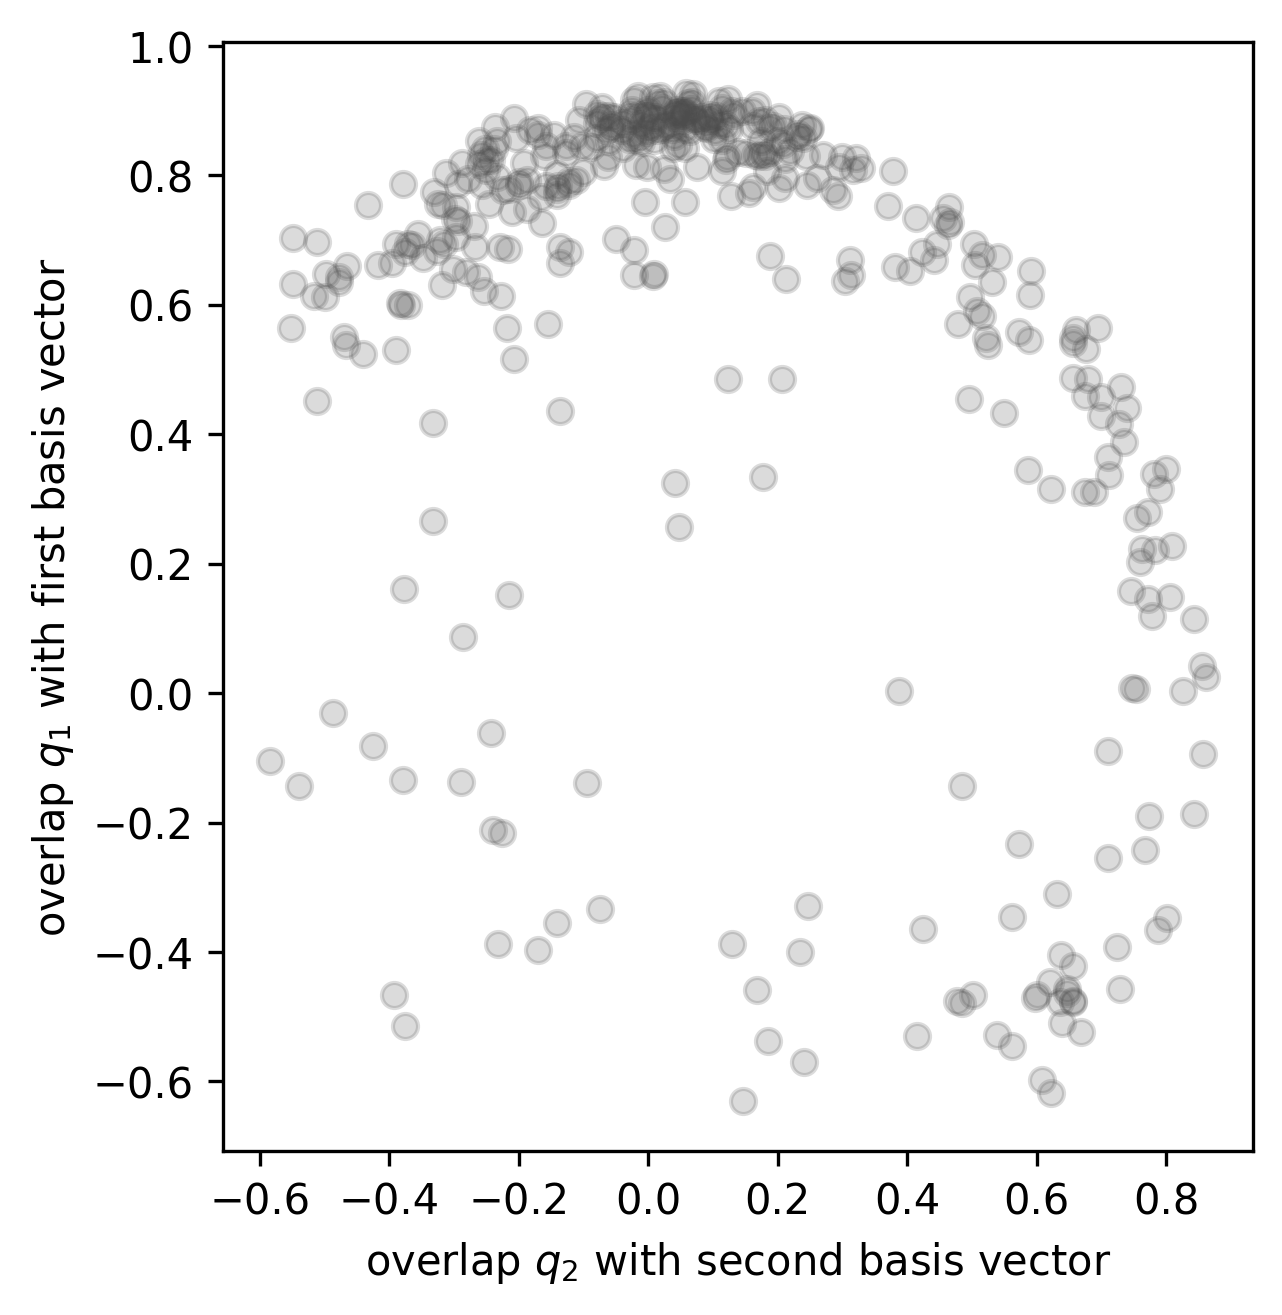

In [71]:
# x = np.linspace(0,1,200)
fig, ax = plt.subplots(dpi=300)
plt.plot(q[1], q[0], 'o', color=(0.3,0.3,0.3,0.2))
# plt.plot(x, np.sqrt(1-x**2), color='k')
ax.set_aspect('equal')
ax.set_ylabel(r'overlap $q_1$ with first basis vector')
ax.set_xlabel(r'overlap $q_2$ with second basis vector')

In [72]:
lam, _ = als.pca(A[j])
tot_var = np.sum(lam)

Text(0.5, 1.0, '0.615 of total variance explained in first 3 modes')

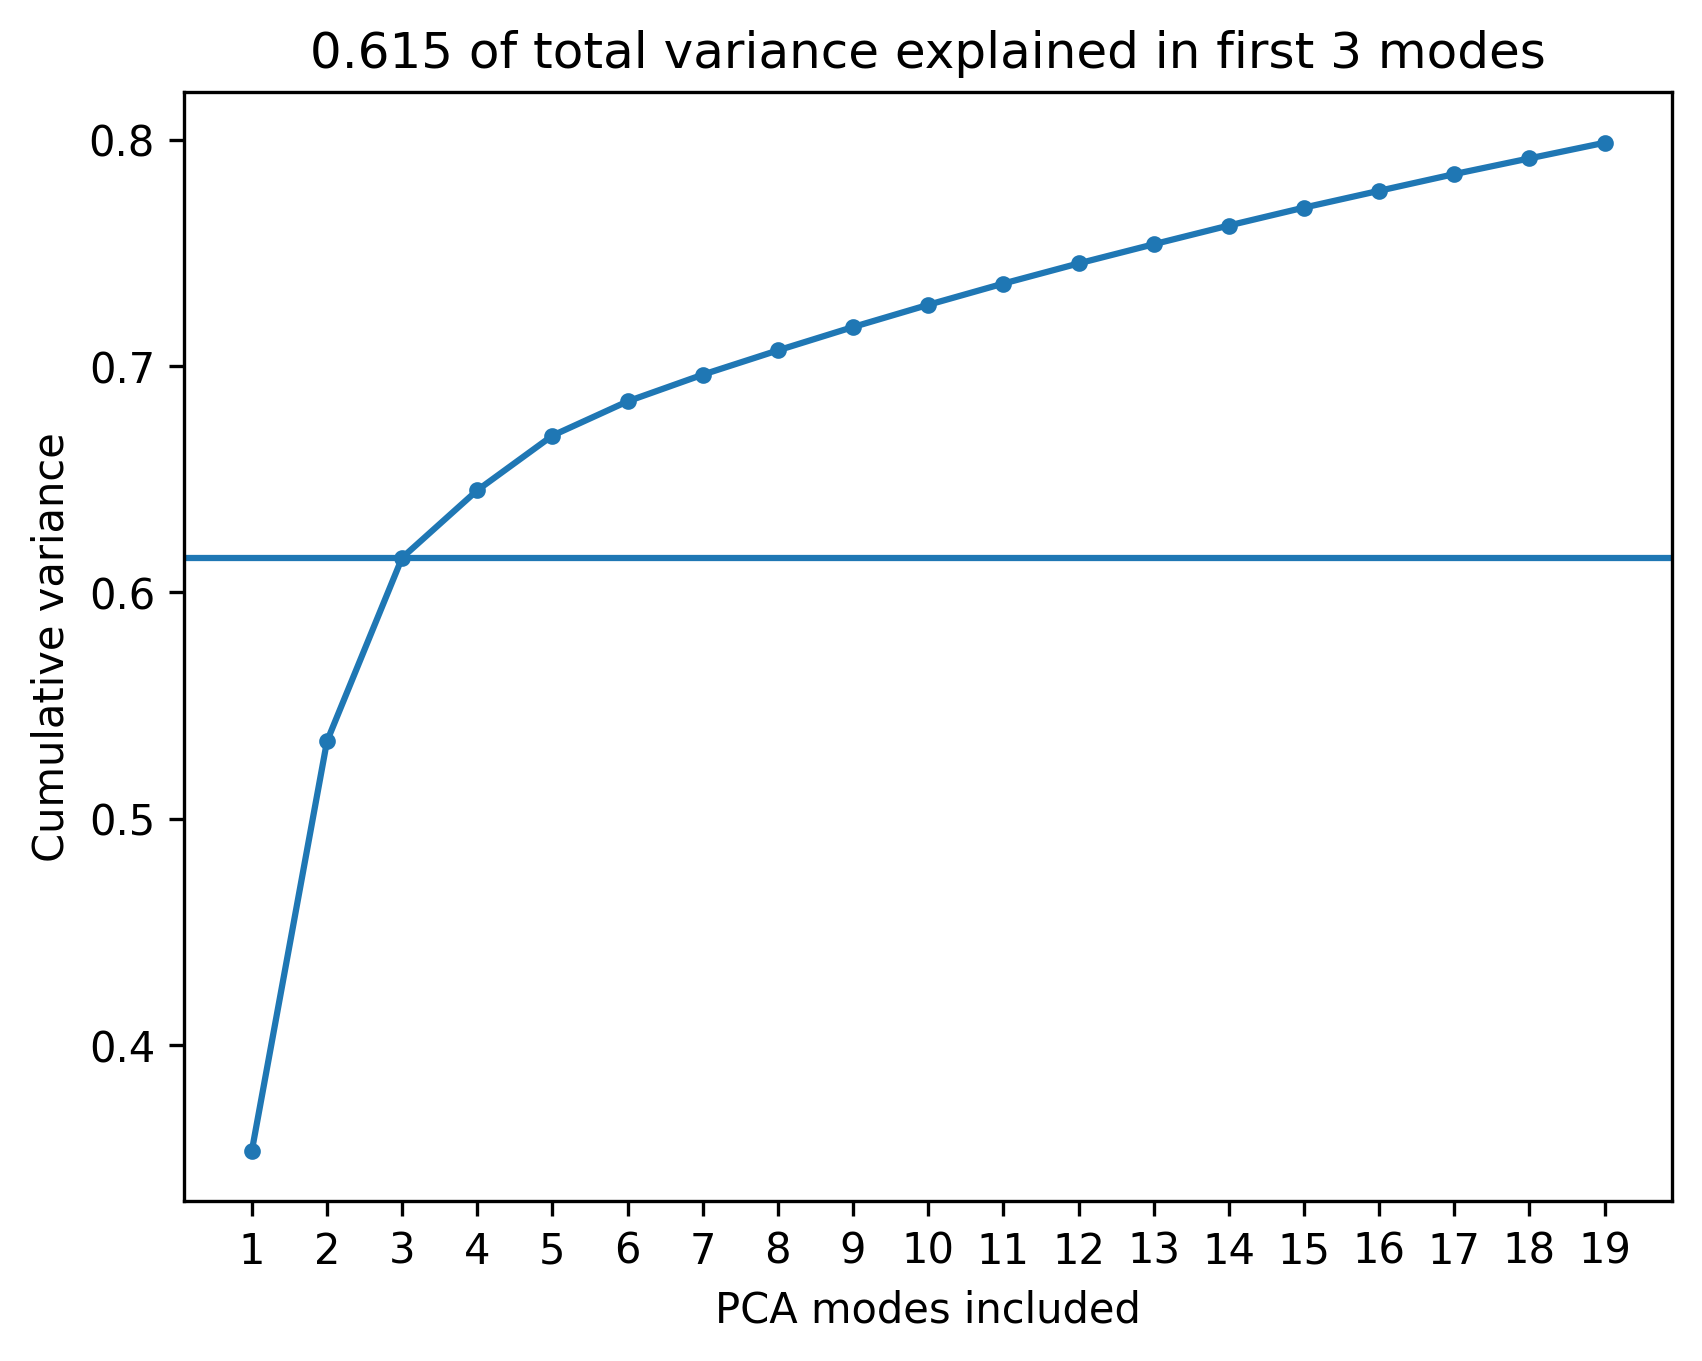

In [73]:
N = 20
n_modes = 3
x1 = np.arange(N-1) + 1
fig, ax = plt.subplots(dpi=300)
y = np.cumsum(lam)[:N-1] / tot_var
y_star = y[n_modes-1]
ax.plot(x1, y, '.-')
ax.axhline(y_star)
ax.set_ylabel("Cumulative variance")
ax.set_xlabel("PCA modes included")
ax.set_xticks(x1)
ax.set_title(f'{y_star:.3f} of total variance explained in first {n_modes} modes')

## "Capture": subspace overlap

The theory here is that two subspaces can be compared (is one spanned by the other?) by first constructing one projection operator for each basis, $P_1$ and $P_2$, then computing $\text{Tr} (P_1 P_2)$. For any single vector $v$, the quantity $v \cdot P_1 \cdot v$ would be the norm of the vector components spanned by $P_1$. Now, given that $P_2$ can be thought of as an outer product sum $v^\alpha_i v^\alpha_j$ of basis vectors, we get the trace formula:

\begin{equation*}
    (P_1)_{ij} v_i^\alpha v_j^\alpha = (P_1)_{ij} (P_2)_{ij}
\end{equation*}

Then finally, in the case that $\text{Span}(P_1) \in \text{Span}(P_2)$, we would have $\text{Tr}(P_1 P_2) = \text{min}(K_1, K_2)$ where $K_i$ are the ranks.

In [17]:
capture = np.eye(len(V_E_buffer_array))
# capture = np.zeros((len(K_array), len(K_array)))
for i in range(len(V_E_buffer_array)):
    for j in range(i):
        capture[i, j] = np.trace(P[i] @ P[j]) / K
        capture[j, i] = capture[i, j]

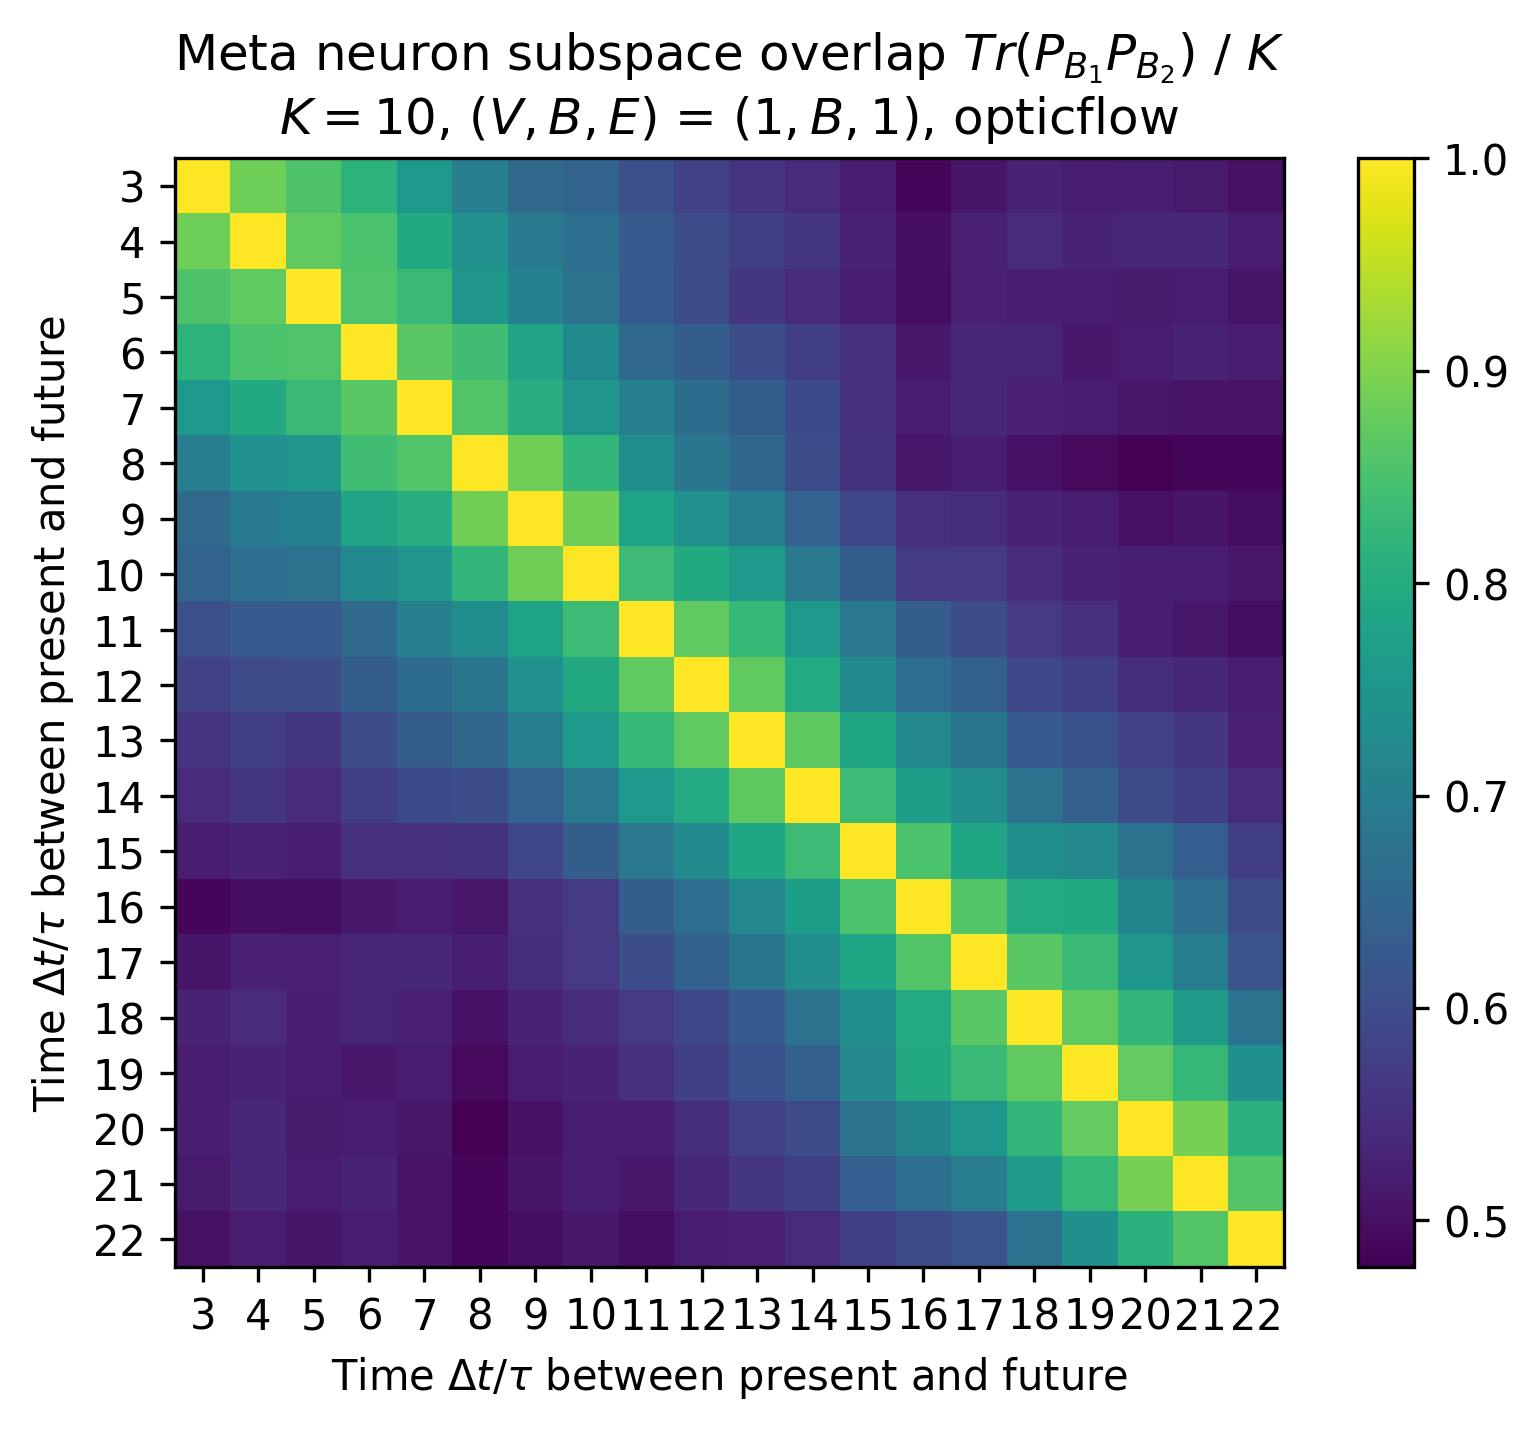

In [18]:
binsize = 1000 / 60
fig, ax = plt.subplots(dpi=300)
im = ax.imshow(capture)
plt.colorbar(im)
ax.set_title("Meta neuron subspace overlap $Tr(P_{B_1} P_{B_2})\  /\  K$ \n" +f"$K=${K}, $(V,B,E)$ = $({V_width},B,{E_width})$, {stim}")
ax.set_xlabel(r"Time $\Delta t / \tau$ between present and future");
ax.set_ylabel(r"Time $\Delta t / \tau$ between present and future");
ax.set_aspect('equal')
ax.set_xticks(np.arange(len(V_E_buffer_array)));
ax.set_xticklabels(V_E_buffer_array + 1);
ax.set_yticks(np.arange(len(V_E_buffer_array)));
ax.set_yticklabels(V_E_buffer_array + 1);
# ax.set_xticklabels(K_array)
# ax.set_yticklabels(K_array)

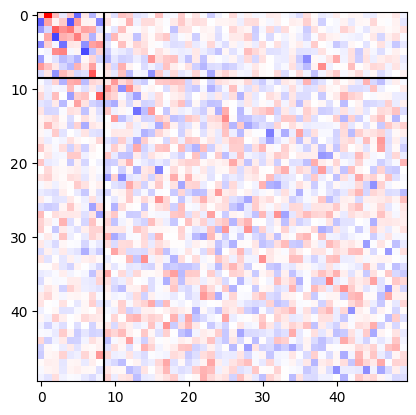

In [46]:
overlap = basis_neurons[0].T @ basis_neurons[-1]
# plt.imshow(np.abs(overlap[:5*K, :5*K]), cmap='Blues')
mx = np.max(np.abs(overlap))
plt.imshow(overlap[:5*K, :5*K], cmap='bwr', vmin=-mx, vmax=mx)
plt.axhline(K-1.5, color='k')
plt.axvline(K-1.5, color='k')

In [ ]:
def collective_modes(modes, saturate=1.5, squared_entries=False, label_string="", plot_params={}):
        '''absolute_value option '''
        num_modes = len(modes)
        fig = plt.figure(constrained_layout=True, figsize=[num_modes,10], **plot_params)
        gs = mpl.gridspec.GridSpec(1, num_modes, figure=fig)
        ax = np.array([None]*(num_modes))
        for n in range(num_modes):
            ax[n] = fig.add_subplot(gs[0,n])
            cur_mode = modes[n]
            if squared_entries: 
                filter_plot = ax[n].imshow(cur_mode**2, interpolation='none', cmap='Blues')
            else:
                vmax = max(np.amax(cur_mode), -np.amin(cur_mode))
                filter_plot = ax[n].imshow(np.abs(cur_mode)**(1/saturate)*np.sign(cur_mode), cmap='bwr', vmax=vmax**(1/saturate), vmin=-vmax**(1/saturate))
            # ax[n].set_aspect('auto')
            ax[n].set_yticks([])
            ax[n].set_xticks([])
            ax[n].set_xlabel(label_string(n))
        return fig, ax

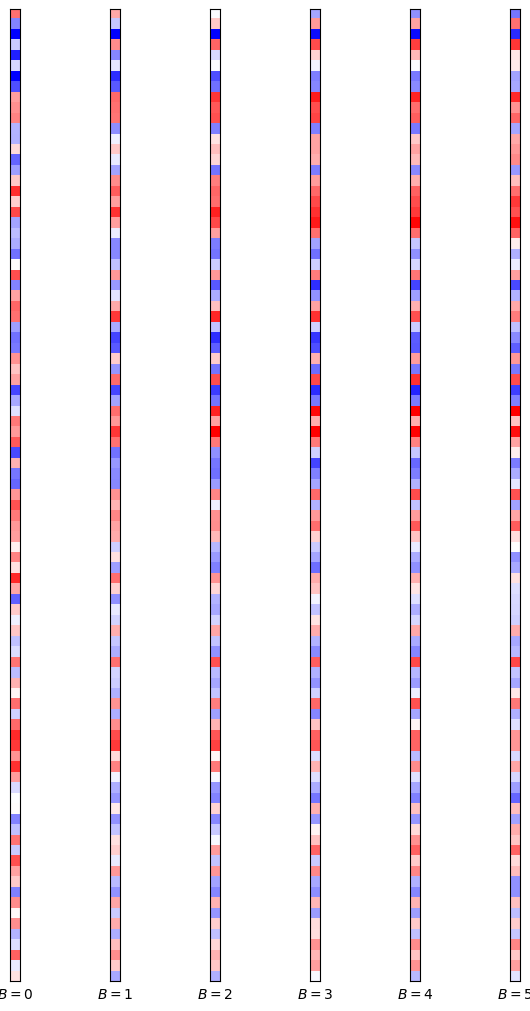

In [ ]:
mode_index = 3
viewing_dims = (V_width, N)
modes = [a[:,mode_index].T.reshape(viewing_dims).T for a in basis_neurons]
collective_modes(modes, label_string=lambda n : f"$B = {n}$");